# SciCite: Interactive Citation Intent Predictor
## Zero-Setup Demo & Testing Playground

**Target Classes:** `METHOD`, `BACKGROUND`, `RESULT`  
**Hosted Public Models (All 6 Configurations Available):**  
- [`Tancsi/scicite-modernbert-section-aware`](https://huggingface.co/Tancsi/scicite-modernbert-section-aware) (Overall Champion - 87.25% Acc, 0.8550 F1)  
- [`Tancsi/scicite-modernbert-text-only`](https://huggingface.co/Tancsi/scicite-modernbert-text-only) (ModernBERT General Baseline - 85.64% Acc, 0.8404 F1)  
- [`Tancsi/scicite-scibert-text-only`](https://huggingface.co/Tancsi/scicite-scibert-text-only) (Domain Specialist, Best on Result Class - 0.8171 F1)  
- [`Tancsi/scicite-scibert-section-aware`](https://huggingface.co/Tancsi/scicite-scibert-section-aware) (SciBERT Domain Section-Aware - 85.31% Acc)  
- [`Tancsi/scicite-distilbert-section-aware`](https://huggingface.co/Tancsi/scicite-distilbert-section-aware) (Fast Distilled Model - 85.64% Acc, 0.8433 F1)  
- [`Tancsi/scicite-distilbert-text-only`](https://huggingface.co/Tancsi/scicite-distilbert-text-only) (DistilBERT Lightweight Baseline - 85.48% Acc)  

### Overview for Evaluators & Lecturers:
This interactive notebook allows anyone to evaluate our fine-tuned citation intent models without running any training, without local GPU requirements, and **without needing any Hugging Face token or API key**.

Models are automatically pulled directly from our public Hugging Face repository (`Tancsi/...`) or loaded from local checkpoints if available.

In [ ]:
# 1. Environment Setup & Tool Imports
import torch
import matplotlib.pyplot as plt
from transformers import pipeline

from src.data import normalize_section_name
from src.utils import plot_prediction_probabilities

print("Environment initialized successfully.")
print(f"CUDA Acceleration available: {torch.cuda.is_available()}")


C:\Repos\scicite-citation-intent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized successfully.
CUDA Acceleration available: True


In [ ]:
# 2. Model Selector across all 6 Fine-Tuned Transformer Models
# ----------------------------------------------------------------------------------------
# AVAILABLE PUBLIC MODELS ON HUGGING FACE HUB (Tancsi/...):
# 1. 'Tancsi/scicite-modernbert-section-aware' -> Overall Leaderboard Champion (87.25% Acc, 0.8550 F1)
# 2. 'Tancsi/scicite-modernbert-text-only'     -> ModernBERT Base without section context
# 3. 'Tancsi/scicite-scibert-text-only'         -> SciBERT Domain Adapted (Best on Result Class: 0.8171 F1)
# 4. 'Tancsi/scicite-scibert-section-aware'     -> SciBERT Domain Model with section context
# 5. 'Tancsi/scicite-distilbert-section-aware'  -> Fast Lightweight Distilled Model (Section-Aware)
# 6. 'Tancsi/scicite-distilbert-text-only'      -> DistilBERT Baseline without section context
# ----------------------------------------------------------------------------------------
SELECTED_MODEL = "Tancsi/scicite-modernbert-section-aware"

print(f"Connecting to Hugging Face Hub to load model: '{SELECTED_MODEL}'...")
device_id = 0 if torch.cuda.is_available() else -1

classifier = pipeline(
    "text-classification",
    model=SELECTED_MODEL,
    top_k=None,  # Returns probability distribution across all 3 target classes
    device=device_id,
)

print(f"Model '{SELECTED_MODEL}' loaded successfully and ready for interactive inference!")


Connecting to Hugging Face Hub to load model: 'Tancsi/scicite-modernbert-section-aware'...



Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 138/138 [00:00<00:00, 2764.67it/s]

Model 'Tancsi/scicite-modernbert-section-aware' loaded successfully and ready for interactive inference!


---
## 3. Interactive Prediction Routine

The function below normalizes the section header into our canonical academic categories (`introduction`, `method`, `result`, `discussion`, `result_discussion`, `other`, `missing`), formats the input string, passes it through the model, and plots the resulting probability distribution.

In [3]:
def predict_citation_intent(citation_sentence: str, section_header: str = ""):
    """Predict citation intent class (method, background, result) and display confidence distribution."""
    # Normalize section header
    clean_section = normalize_section_name(section_header) if section_header else "missing"
    
    # Apply structured conditioning prefix if section-aware model
    if "section-aware" in SELECTED_MODEL.lower():
        formatted_input = f"Section: {clean_section}. Citation: {citation_sentence.strip()}"
    else:
        formatted_input = citation_sentence.strip()
        
    raw_preds = classifier(formatted_input)[0]
    
    # Build probability mapping
    prob_dict = {
        item["label"].capitalize(): float(item["score"])
        for item in sorted(raw_preds, key=lambda x: x["label"])
    }
    top_pred = max(raw_preds, key=lambda x: x["score"])
    winner_label = top_pred["label"].capitalize()
    winner_pct = top_pred["score"] * 100
    
    # Print structured diagnosis
    print("=" * 75)
    print(f"PREDICTION:  [{winner_label.upper()}]  ({winner_pct:.1f}% confidence)")
    print("=" * 75)
    print(f"Raw Sentence:     \"{citation_sentence.strip()}\"")
    print(f"Section Header:   '{section_header}' -> Canonical Category: '{clean_section}'")
    print(f"Conditioned Text: \"{formatted_input}\"")
    print("-" * 75)
    for cls_name, score in prob_dict.items():
        bar_repr = "#" * int(score * 30)
        print(f"  - {cls_name:<12} {score*100:>5.1f}%  |{bar_repr:<30}|")
    print("=" * 75)
    
    # Render horizontal probability distribution
    fig = plot_prediction_probabilities(
        prob_dict,
        predicted_label=winner_label,
        title=f"Intent Prediction: {winner_label.upper()} ({winner_pct:.1f}%)",
    )
    plt.show()


---
## 4. Custom Sentence Playground (Edit & Run)

Lecturers and evaluators can modify the two variables below with any arbitrary text to test the model live.

PREDICTION:  [METHOD]  (99.6% confidence)
Raw Sentence:     "We trained the deep neural network using the AdamW optimizer with a learning rate of 2e-5 and linear warmup as described by Loshchilov et al. [2018]."
Section Header:   'Methodology' -> Canonical Category: 'other'
Conditioned Text: "Section: other. Citation: We trained the deep neural network using the AdamW optimizer with a learning rate of 2e-5 and linear warmup as described by Loshchilov et al. [2018]."
---------------------------------------------------------------------------
  - Background     0.4%  |                              |
  - Method        99.6%  |############################# |
  - Result         0.0%  |                              |


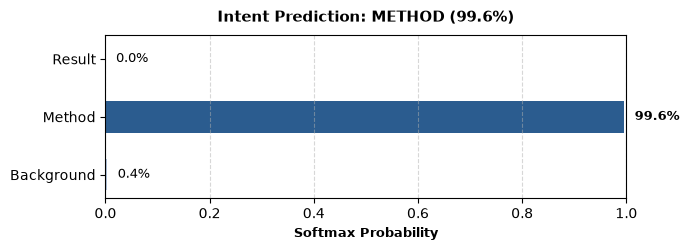

In [4]:
# =========================================================================================
# EDIT THESE TWO VARIABLES TO TEST ANY CUSTOM CITATION:
# =========================================================================================
SECTION_HEADER = "Methodology"  # e.g., 'Introduction', 'Methods', 'Results', 'Discussion', or ''
CITATION_SENTENCE = "We trained the deep neural network using the AdamW optimizer with a learning rate of 2e-5 and linear warmup as described by Loshchilov et al. [2018]."
# =========================================================================================

predict_citation_intent(CITATION_SENTENCE, SECTION_HEADER)


---
## 5. Pre-Loaded Scientific Benchmark Test Cases

Below are 5 curated real-world examples representing diverse rhetorical functions and challenging edge cases:


>>> RUNNING BENCHMARK Case 1: Pure Methodology (Algorithm / Tool Citation) <<<
PREDICTION:  [METHOD]  (99.5% confidence)
Raw Sentence:     "All molecular dynamics trajectories were integrated using the GROMACS 2021 package (Abraham et al., 2015) with the CHARMM36m force field."
Section Header:   '3. Experimental Setup' -> Canonical Category: 'method'
Conditioned Text: "Section: method. Citation: All molecular dynamics trajectories were integrated using the GROMACS 2021 package (Abraham et al., 2015) with the CHARMM36m force field."
---------------------------------------------------------------------------
  - Background     0.4%  |                              |
  - Method        99.5%  |############################# |
  - Result         0.0%  |                              |


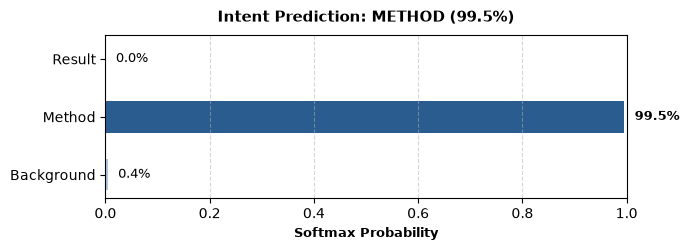


>>> RUNNING BENCHMARK Case 2: Pure Literature Background (Prior Theory / Related Work) <<<
PREDICTION:  [BACKGROUND]  (90.4% confidence)
Raw Sentence:     "Prior studies have consistently demonstrated that transfer learning improves low-resource performance across natural language processing benchmarks (Devlin et al., 2018; Radford et al., 2019)."
Section Header:   '1. Introduction' -> Canonical Category: 'introduction'
Conditioned Text: "Section: introduction. Citation: Prior studies have consistently demonstrated that transfer learning improves low-resource performance across natural language processing benchmarks (Devlin et al., 2018; Radford et al., 2019)."
---------------------------------------------------------------------------
  - Background    90.4%  |###########################   |
  - Method         6.4%  |#                             |
  - Result         3.3%  |                              |


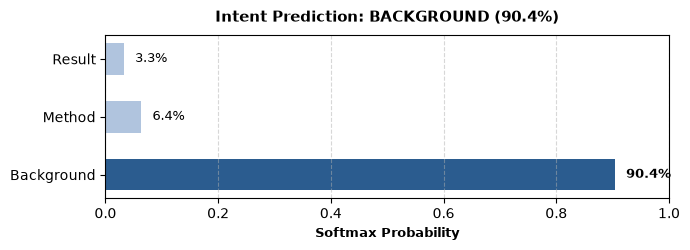


>>> RUNNING BENCHMARK Case 3: Empirical Result (Comparative Performance / Numerical Contrast) <<<
PREDICTION:  [RESULT]  (57.0% confidence)
Raw Sentence:     "Our proposed architecture achieves 87.25% accuracy, significantly outperforming the 83.54% reported by the baseline implementation of Cohan et al. (2019)."
Section Header:   '4. Results and Analysis' -> Canonical Category: 'result'
Conditioned Text: "Section: result. Citation: Our proposed architecture achieves 87.25% accuracy, significantly outperforming the 83.54% reported by the baseline implementation of Cohan et al. (2019)."
---------------------------------------------------------------------------
  - Background    19.6%  |#####                         |
  - Method        23.4%  |#######                       |
  - Result        57.0%  |#################             |


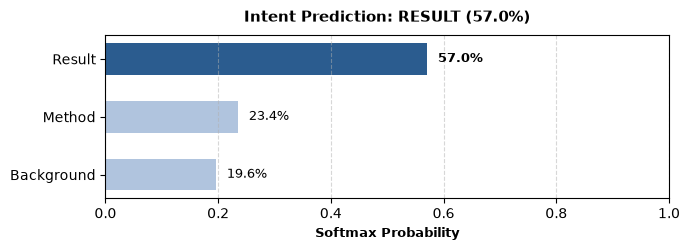


>>> RUNNING BENCHMARK Case 4: Context-Rescued Ambiguity (Background Syntax in Methods Section) <<<
PREDICTION:  [METHOD]  (94.0% confidence)
Raw Sentence:     "In diabetes mellitus, the choice of drugs or dosages is influenced by GFR [57], which we used as our primary exclusion criterion."
Section Header:   '2. Materials and Methods' -> Canonical Category: 'method'
Conditioned Text: "Section: method. Citation: In diabetes mellitus, the choice of drugs or dosages is influenced by GFR [57], which we used as our primary exclusion criterion."
---------------------------------------------------------------------------
  - Background     5.9%  |#                             |
  - Method        94.0%  |############################  |
  - Result         0.1%  |                              |


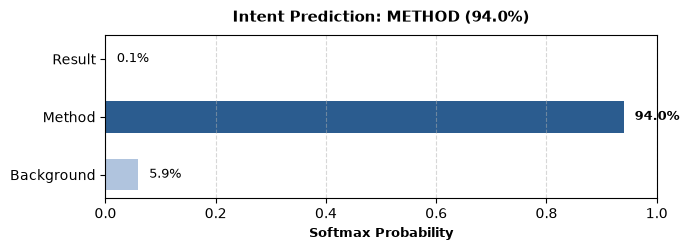


>>> RUNNING BENCHMARK Case 5: Result vs. Background Boundary (Discussion Comparison) <<<
PREDICTION:  [RESULT]  (99.7% confidence)
Raw Sentence:     "Consistent with the observations of Smith et al. (2020), our measured binding affinity decreased tenfold under acidic conditions."
Section Header:   '5. Discussion' -> Canonical Category: 'discussion'
Conditioned Text: "Section: discussion. Citation: Consistent with the observations of Smith et al. (2020), our measured binding affinity decreased tenfold under acidic conditions."
---------------------------------------------------------------------------
  - Background     0.2%  |                              |
  - Method         0.1%  |                              |
  - Result        99.7%  |############################# |


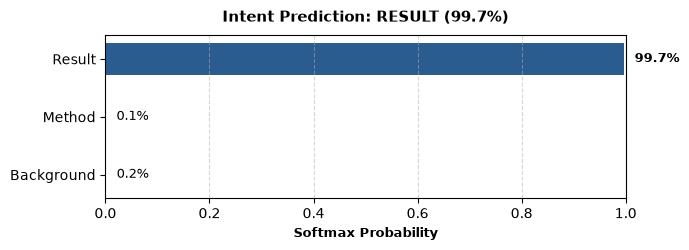

In [5]:
BENCHMARK_CASES = [
    {
        "case_name": "Case 1: Pure Methodology (Algorithm / Tool Citation)",
        "section": "3. Experimental Setup",
        "sentence": "All molecular dynamics trajectories were integrated using the GROMACS 2021 package (Abraham et al., 2015) with the CHARMM36m force field.",
    },
    {
        "case_name": "Case 2: Pure Literature Background (Prior Theory / Related Work)",
        "section": "1. Introduction",
        "sentence": "Prior studies have consistently demonstrated that transfer learning improves low-resource performance across natural language processing benchmarks (Devlin et al., 2018; Radford et al., 2019).",
    },
    {
        "case_name": "Case 3: Empirical Result (Comparative Performance / Numerical Contrast)",
        "section": "4. Results and Analysis",
        "sentence": "Our proposed architecture achieves 87.25% accuracy, significantly outperforming the 83.54% reported by the baseline implementation of Cohan et al. (2019).",
    },
    {
        "case_name": "Case 4: Context-Rescued Ambiguity (Background Syntax in Methods Section)",
        "section": "2. Materials and Methods",
        "sentence": "In diabetes mellitus, the choice of drugs or dosages is influenced by GFR [57], which we used as our primary exclusion criterion.",
    },
    {
        "case_name": "Case 5: Result vs. Background Boundary (Discussion Comparison)",
        "section": "5. Discussion",
        "sentence": "Consistent with the observations of Smith et al. (2020), our measured binding affinity decreased tenfold under acidic conditions.",
    },
]

for idx, test_case in enumerate(BENCHMARK_CASES, start=1):
    print(f"\n>>> RUNNING BENCHMARK {test_case['case_name']} <<<")
    predict_citation_intent(test_case["sentence"], test_case["section"])
